# 03 - Random Forest

Run all cells in order. An ensemble of 150 trees that can model nonlinear relationships. The 2025 evaluation cohort was previously inspected. Training is performed twice and may take several minutes.

### How to run a cell
Click inside a cell, then click the **Run (▶)** button in the Jupyter toolbar. You can also press **Shift + Enter**. Start with the first cell and run the cells in order; later cells use variables created by earlier ones.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, f1_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits
DATA = Path('data/final_matched_2021_2025.csv.gz')
assert DATA.exists(), 'Start Jupyter in the project folder.'
LABELS = np.array(['Fatal','Serious','Slight'])
from sklearn.ensemble import RandomForestClassifier

## 1. Load the finalized dataset and split by year

In [2]:
data = pd.read_csv(DATA, dtype={'collision_index': str}, float_precision='round_trip')
train = data[data.year.isin([2021,2022,2023])].copy()
validation = data[data.year == 2024].copy()
test = data[data.year == 2025].copy()
assert (len(train),len(validation),len(test)) == (60945,19176,19062)
display(pd.DataFrame({'group':['Training (2021-23)','Validation (2024)','Evaluation (2025)'],'rows':[len(train),len(validation),len(test)]}))
display(test.severity.value_counts().reindex(['Slight','Serious','Fatal']).to_frame('2025 collisions'))

,group,rows
0,Training (2021-23),60945
1,Validation (2024),19176
2,Evaluation (2025),19062


,2025 collisions
severity,
Slight,14639
Serious,4219
Fatal,204


## 2. Select the seven feature groups

ID, year, count-point ID and severity are metadata or target, never predictors.

In [3]:
categorical = ['road_type','weather_conditions','road_surface_conditions']
numeric = ['speed_limit','time_sin','time_cos','aadf_motor_vehicles_per_day',
           'time_sin_2','time_cos_2','time_sin_3','time_cos_3',
           'vehicle_composition_cycle','vehicle_composition_motorcycle',
           'vehicle_composition_car_taxi','vehicle_composition_bus',
           'vehicle_composition_goods','vehicle_composition_other']
vehicle_flags = sorted(c for c in data.columns if c.startswith('vehicle_type_'))
features = categorical + numeric + vehicle_flags
assert set(features) == set(data.columns) - {'collision_index','severity','year','count_point_id'}
print(f'{len(features)} columns represent the seven input groups:')
print(features)

40 columns represent the seven input groups:
['road_type', 'weather_conditions', 'road_surface_conditions', 'speed_limit', 'time_sin', 'time_cos', 'aadf_motor_vehicles_per_day', 'time_sin_2', 'time_cos_2', 'time_sin_3', 'time_cos_3', 'vehicle_composition_cycle', 'vehicle_composition_motorcycle', 'vehicle_composition_car_taxi', 'vehicle_composition_bus', 'vehicle_composition_goods', 'vehicle_composition_other', 'vehicle_type_1', 'vehicle_type_10', 'vehicle_type_11', 'vehicle_type_16', 'vehicle_type_17', 'vehicle_type_18', 'vehicle_type_19', 'vehicle_type_2', 'vehicle_type_20', 'vehicle_type_21', 'vehicle_type_22', 'vehicle_type_23', 'vehicle_type_3', 'vehicle_type_33', 'vehicle_type_4', 'vehicle_type_5', 'vehicle_type_8', 'vehicle_type_9', 'vehicle_type_90', 'vehicle_type_97', 'vehicle_type_98', 'vehicle_type_99', 'vehicle_type_missing']


## 3. Prepare the input columns

The model needs numbers. We fill missing category values, then turn categories into columns using one-hot encoding. We fill missing numeric values with the training median and add missing-value indicators. The vehicle-type columns are already numeric, so they pass through unchanged.

The pipeline learns these values from training data during `fit()`; it does not learn them from the evaluation data.

In [4]:
categorical_pipeline = Pipeline([
    ('missing', SimpleImputer(strategy='constant', fill_value=-1)),
    ('one_hot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
preprocessor = ColumnTransformer([
    ('categories', categorical_pipeline, categorical),
    ('numeric', SimpleImputer(strategy='median', add_indicator=True), numeric),
    ('vehicles', 'passthrough', vehicle_flags)
])
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categories', ...), ('numeric', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and 

## 4. Define the model

These are the fixed settings used for the earlier comparison; this notebook does not repeat the previous hyperparameter search.

In [5]:
model = Pipeline([('prepare', preprocessor), ('model', RandomForestClassifier(n_estimators=150, max_depth=14, min_samples_leaf=10, random_state=42, n_jobs=2))])
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prepare', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categories', ...), ('numeric', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, defaul

## 5. Train on 2021-2023

Labels are encoded Fatal = 0, Serious = 1, Slight = 2. Training weights are 5, 2 and 1 respectively.

In [6]:
y_train = pd.Categorical(train.severity, categories=LABELS).codes
assert set(y_train) == {0,1,2}
# Limit CPU threads to keep the demo manageable.
with threadpool_limits(limits=2):
    sample_weights = train.severity.map({'Slight':1,'Serious':2,'Fatal':5}).to_numpy()
    model.fit(train[features], y_train, model__sample_weight=sample_weights)
    validation_probabilities = model.predict_proba(validation[features])
print('Training complete:', validation_probabilities.shape)

Training complete: (19176, 3)


## 6. Choose the decision weights using 2024

We try a few weights for Serious and Fatal predictions. For each pair, we calculate macro F1 on the validation data and keep the best pair. Slight always has weight 1. The adjusted scores help choose a class; they are not calibrated probabilities.

In [7]:
best_score = -1

for serious_weight in [0.75, 1, 1.25, 1.5, 2, 3]:
    for fatal_weight in [1, 2, 4, 6, 8, 12]:
        weights = np.array([fatal_weight, serious_weight, 1])
        predictions = LABELS[(validation_probabilities * weights).argmax(axis=1)]
        score = f1_score(validation.severity, predictions, labels=LABELS,
                         average='macro', zero_division=0)

        if score > best_score:
            best_score = score
            decision_weights = weights

print('Best validation macro F1:', round(best_score, 4))
print('Weights for Fatal, Serious, Slight:', decision_weights)

Best validation macro F1: 0.4317
Weights for Fatal, Serious, Slight: [4.  1.5 1. ]


## 7. Train again and evaluate on 2025

Now that the weights are chosen, we train the same model on 2021-2024. We keep the weights fixed and use the 2025 rows to calculate the results. The 2025 rows were already inspected in earlier work, so they are not a fresh final test.

In [8]:
development = pd.concat([train, validation], ignore_index=True)
y_development = pd.Categorical(development.severity, categories=LABELS).codes
# Limit CPU threads to keep the demo manageable.
with threadpool_limits(limits=2):
    sample_weights = development.severity.map({'Slight':1,'Serious':2,'Fatal':5}).to_numpy()
    model.fit(development[features], y_development, model__sample_weight=sample_weights)
    test_probabilities = model.predict_proba(test[features])
print('Evaluation rows:', len(test))

Evaluation rows: 19062


2025 accuracy: 70.19%
2025 macro F1: 0.4308
              precision    recall  f1-score   support

      Slight       0.81      0.82      0.81     14639
     Serious       0.36      0.33      0.34      4219
       Fatal       0.10      0.22      0.14       204

    accuracy                           0.70     19062
   macro avg       0.42      0.46      0.43     19062
weighted avg       0.70      0.70      0.70     19062



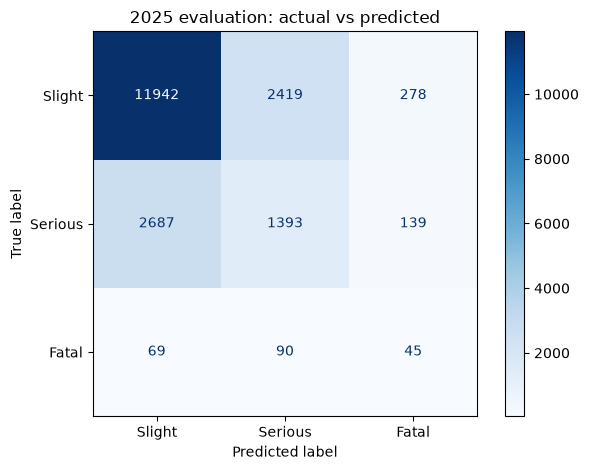

In [9]:
predicted = LABELS[(test_probabilities * decision_weights).argmax(axis=1)]
print('2025 accuracy:', f'{accuracy_score(test.severity, predicted):.2%}')
print('2025 macro F1:', f'{f1_score(test.severity, predicted, labels=LABELS, average="macro", zero_division=0):.4f}')
print(classification_report(test.severity, predicted, labels=['Slight','Serious','Fatal'], zero_division=0))
ConfusionMatrixDisplay.from_predictions(test.severity, predicted, labels=['Slight','Serious','Fatal'], cmap='Blues', values_format='d')
plt.title('2025 evaluation: actual vs predicted'); plt.tight_layout(); plt.show()

The recorded accuracy for this configuration was **70.19%**. Inspect any differences rather than altering the results. Accuracy alone does not establish good Serious or Fatal detection.

## 8. Final comparison

All three models use the same evaluation rows and full 2021 data.

In [10]:
comparison = pd.read_csv('results/final_model_comparison.csv')
display(comparison)
print('Always predicting Slight would score', f'{(test.severity == "Slight").mean():.2%}', 'accuracy and miss all Serious and Fatal crashes.')

,Model,Accuracy (%),Slight recall (%),Serious recall (%),Fatal recall (%),Macro F1
0,Logistic Regression,70.60,82.89,30.79,12.25,0.4172
1,Random Forest,70.19,81.58,33.02,22.06,0.4308
2,XGBoost,68.51,76.98,41.83,12.75,0.4285


Always predicting Slight would score 76.80% accuracy and miss all Serious and Fatal crashes.


## Questions to be ready for

- Why can accuracy be high while Fatal recall is low?
- Why select multipliers on 2024 instead of 2025?
- Is AADF actual traffic density?
- Are vehicle types known before a collision?
- Why are adjusted scores not calibrated probabilities?